In [2]:
import os
import pandas as pd

In [3]:
def datasets():    
    for file in sorted(os.listdir("split_by_compound")):
        yield pd.read_csv("split_by_compound/"+file, index_col=0)


In [4]:
for data in datasets():
    print(data.train.sum()/len(data))

0.7955449482895783
0.7931583134447097
0.7971360381861575
0.7971360381861575
0.7907716785998409
0.7947494033412887
0.7923627684964201
0.7891805887032617
0.7979315831344471
0.8011137629276054


<Axes: xlabel='pIC50', ylabel='Count'>

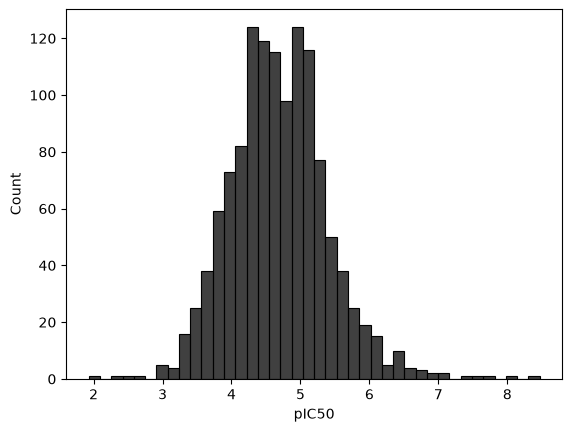

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data, x="pIC50", color="black")

In [6]:
data.pIC50.describe()

count    1257.000000
mean        4.688346
std         0.708047
min         1.929482
25%         4.221849
50%         4.671620
75%         5.124939
max         8.468521
Name: pIC50, dtype: float64

In [7]:
(10**(-data.pIC50)).describe()

count    1.257000e+03
mean     7.372389e-05
std      3.763044e-04
min      3.400000e-09
25%      7.500000e-06
50%      2.130000e-05
75%      6.000000e-05
max      1.176300e-02
Name: pIC50, dtype: float64

In [9]:
for i, df in enumerate(datasets()):
    df["Split Number"] = i
    if i == 0:
        df_joined = df
    else:
        df_joined = pd.concat([df, df_joined])
df_joined["Subset"] = "Test"
df_joined.loc[df_joined.train, "Subset"] = "Train"

/tmp/ipykernel_12645/3722871850.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["Split Number"] = i
/tmp/ipykernel_12645/3722871850.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_joined["Subset"] = "Test"


<Axes: xlabel='Split Number', ylabel='pIC50'>

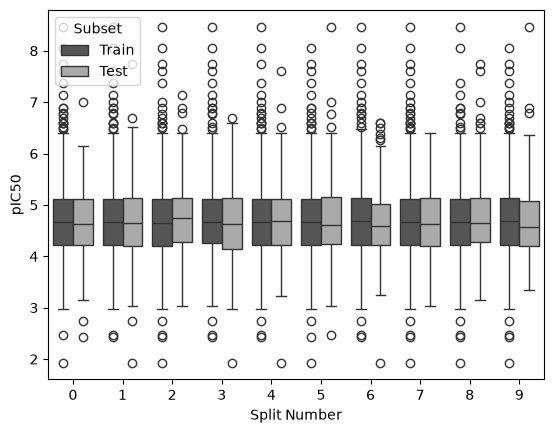

In [10]:
sns.boxplot(df_joined, x="Split Number", y="pIC50", hue="Subset", palette="gray")

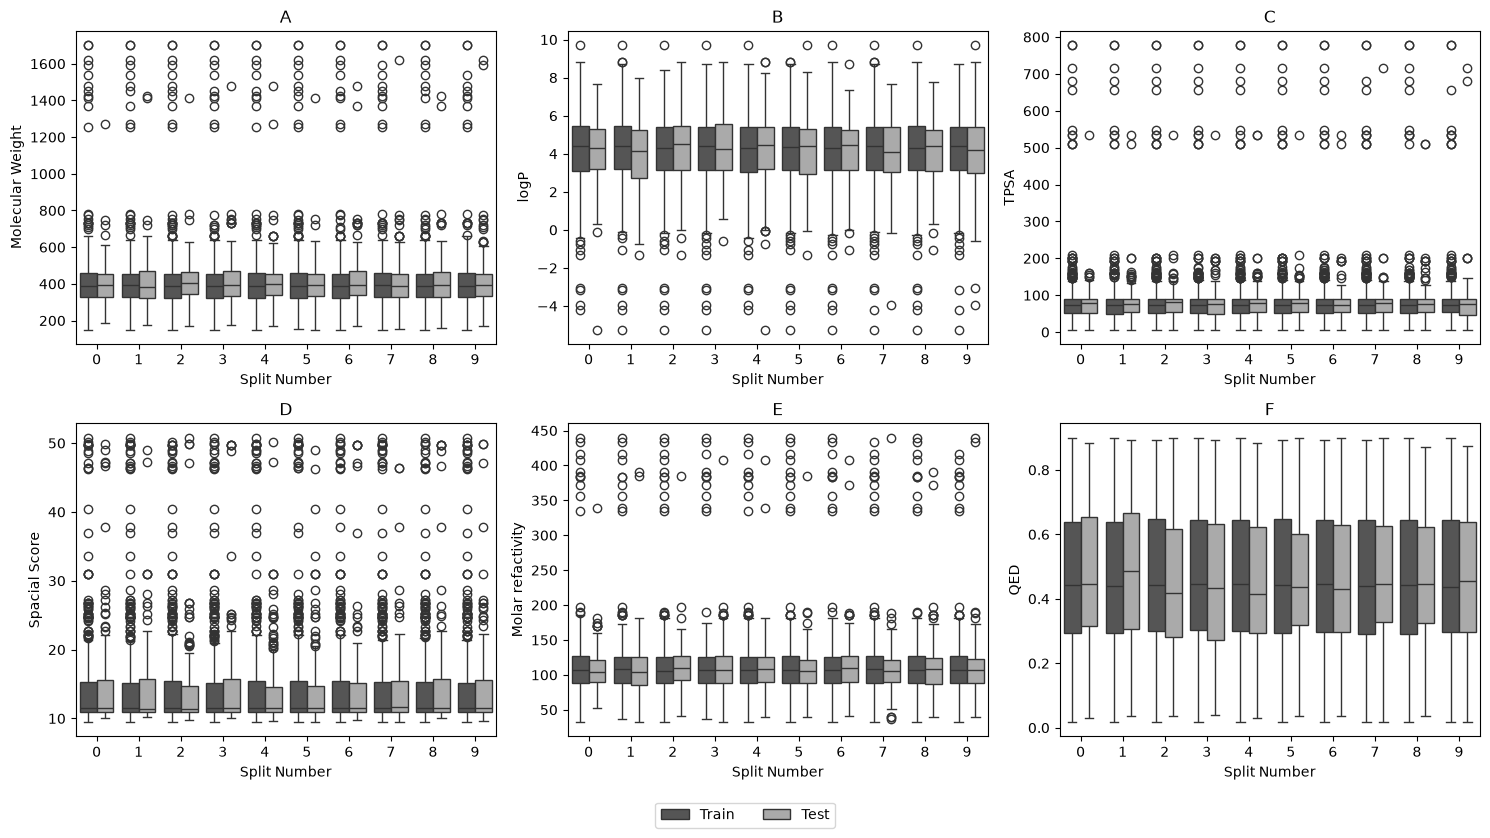

In [11]:
fig, axes = plt.subplots(2, 3, figsize = (15,8))

sns.boxplot(df_joined, x="Split Number", y="MolWt", hue="Subset", palette="gray", ax=(ax:=axes[0][0]))
ax.set_ylabel("Molecular Weight")
ax.get_legend().remove()
ax.set_title("A")

sns.boxplot(df_joined, x="Split Number", y="MolLogP", hue="Subset", palette="gray", ax=(ax:=axes[0][1]))
ax.set_ylabel("logP")
ax.get_legend().remove()
ax.set_title("B")

sns.boxplot(df_joined, x="Split Number", y="TPSA", hue="Subset", palette="gray", ax=(ax:=axes[0][2]))
ax.get_legend().remove()
ax.set_title("C")

sns.boxplot(df_joined, x="Split Number", y="SPS", hue="Subset", palette="gray", ax=(ax:=axes[1][0]))
ax.set_ylabel("Spacial Score")
ax.get_legend().remove()
ax.set_title("D")

sns.boxplot(df_joined, x="Split Number", y="MolMR", hue="Subset", palette="gray", ax=(ax:=axes[1][1]))
ax.set_ylabel("Molar refactivity")
ax.get_legend().remove()
ax.set_title("E")

sns.boxplot(df_joined, x="Split Number", y="qed", hue="Subset", palette="gray", ax=(ax:=axes[1][2]))
ax.set_ylabel("QED")
ax.get_legend().remove()
ax.set_title("F")

handles, labels = axes[0][0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.05), ncol=3)
fig.tight_layout()


In [12]:
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
import numpy as np
from collections import defaultdict

results = defaultdict(list)

for dataset in datasets():
    for species in dataset.target_organism.unique():
        train = dataset[dataset.target_organism.eq(species) & dataset.train]
        test = dataset[dataset.target_organism.eq(species) & ~dataset.train]
        ftrain = train.iloc[:,5:].to_numpy()
        ftest = test.iloc[:,5:].to_numpy()
        scaler = StandardScaler()
        ftrain[:,768:900] = scaler.fit_transform(ftrain[:,768:900]) 
        ftest[:,768:900] = scaler.transform(ftest[:,768:900]) 
        model = RidgeCV()
        model.fit(ftrain, train.pIC50)
        y_pred = model.predict(ftest)
        results[species].append(r2_score(test.pIC50, y_pred))

for species in results:
    print(species, np.mean(results[species]), np.std(results[species]))
    

Staphylococcus aureus 0.4049197734604998 0.08113899090518271
Salmonella enterica subsp. enterica serovar Typhimurium 0.262605281300457 0.07284016061692282
Escherichia coli 0.41720076201978273 0.21500929256090415
Mycolicibacterium smegmatis 0.3458274837122174 0.3494480738603989
Pseudoalteromonas ulvae -0.009264179992081623 0.8194469606065763
Streptococcus mutans 0.1798893672556045 0.45590554808234823
Raoultella planticola 0.5268106031423472 0.25221660441686455
Bacillus subtilis 0.5282602799130098 0.13690486821374853
